# 04 - Models

Question: do weather, vegetation, elevation and land-cover features beat the best baseline (climatology + 0.29 x last departure, RMSE 4.21 C on the same rows)?

Ladder: ridge regression, then LightGBM. Split from 02: train 2003-2018, test 2019-2023.

In [2]:
import pandas as pd
import numpy as np

df = pd.read_parquet('../data/processed/dataset.parquet')
df['comp'] = df.groupby(['pid', 'year']).cumcount()
df = df.dropna(subset=['lst_target'])


print(df.columns.tolist())
print(df.dtypes.value_counts())
print(df.isna().mean().round(3).sort_values(ascending=False).head(12))

['date', 'lat', 'lon', 'lst_prev', 'lst_target', 'ndvi_lag', 'pid', 'qc_prev', 'qc_target', 'dewpoint', 'precip_8d', 'soil_moisture', 'solar_8d', 'doy', 'year', 'elevation', 'lc10', 'lc100', 'lc20', 'lc30', 'lc40', 'lc50', 'lc60', 'lc70', 'lc80', 'lc90', 'lc95', 't_mand', 't_err', 'p_mand', 'p_err', 'comp']
float64    19
int64      12
str         1
Name: count, dtype: int64
lst_prev         0.167
soil_moisture    0.051
precip_8d        0.051
dewpoint         0.051
solar_8d         0.051
ndvi_lag         0.001
lat              0.000
date             0.000
qc_prev          0.000
pid              0.000
lst_target       0.000
lon              0.000
dtype: float64


In [3]:
FEATURES = ['lst_prev', 'ndvi_lag', 'dewpoint', 'precip_8d', 'soil_moisture', 'solar_8d',
            'doy', 'lat', 'lon', 'elevation',
            'lc10', 'lc20', 'lc30', 'lc40', 'lc50', 'lc60', 'lc70', 'lc80', 'lc90', 'lc95', 'lc100',
            'p_mand', 'p_err']
TARGET = 'lst_target'

train = df[df['year'] <= 2018]
test = df[df['year'] >= 2019]

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

same_rows = (test['comp'] > 0) & test['lst_prev'].notna()
print(X_train.shape, X_test.shape)
print(same_rows.sum())
missing = X_train.isna().mean()
print(missing[missing > 0].round(3))

(310577, 23) (99840, 23)
76310
lst_prev         0.173
ndvi_lag         0.001
dewpoint         0.051
precip_8d        0.051
soil_moisture    0.051
solar_8d         0.051
dtype: float64


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

def rmse(y, pred):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(pred)) ** 2)))

ridge = make_pipeline(
    SimpleImputer(strategy='median', add_indicator = True),
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge.fit(X_train, y_train)
pred = ridge.predict(X_test)

print('ridge, same rows  ', round(rmse(y_test[same_rows], pred[same_rows.to_numpy()]), 3))
print('ridge, all rows   ', round(rmse(y_test, pred), 3))
print('ridge, train rows ', round(rmse(y_train, ridge.predict(X_train)), 3))

ridge, same rows   4.069
ridge, all rows    4.04
ridge, train rows  3.748


In [5]:
import lightgbm as lgb

fit = train[train['year'] <= 2015]
val = train[train['year'] >= 2016]

params = dict(learning_rate=0.05, num_leaves=15, min_child_samples=20,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
              random_state=42, verbose=-1)

probe = lgb.LGBMRegressor(n_estimators=3000, **params)
probe.fit(fit[FEATURES], fit[TARGET], 
        eval_set=[(val[FEATURES], val[TARGET])], eval_metric='rmse',
        callbacks=[lgb.early_stopping(50, verbose=False)])

n_trees = probe.best_iteration_
print(n_trees, round(probe.best_score_['valid_0']['rmse'], 3))

lgbm = lgb.LGBMRegressor(n_estimators=n_trees, **params)
lgbm.fit(X_train, y_train)
pred_lgbm = lgbm.predict(X_test)

print('same rows', round(rmse(y_test[same_rows], pred_lgbm[same_rows.to_numpy()]), 3))
print('all rows ', round(rmse(y_test, pred_lgbm), 3))
print('train    ', round(rmse(y_train, lgbm.predict(X_train)), 3))


c:\Users\Joshu\PortfolioExpansionProjects\ML2\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


329 3.912
same rows 4.063
all rows  4.026
train     3.295


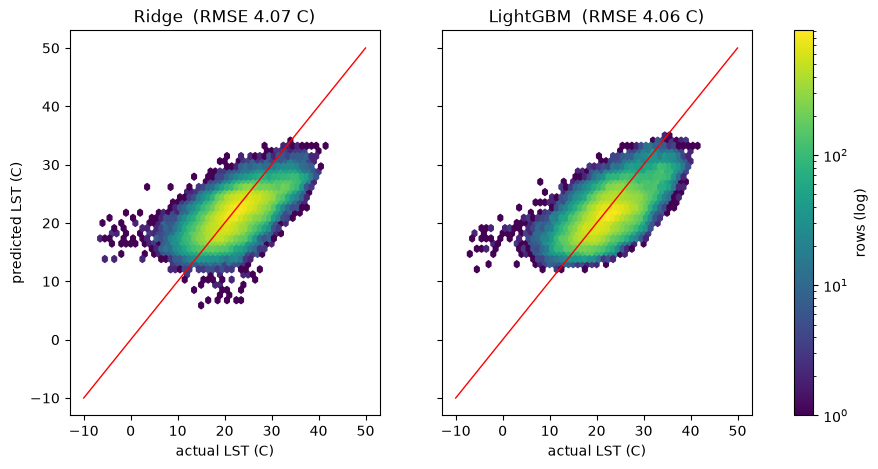

In [6]:
import matplotlib.pyplot as plt

mask = same_rows.to_numpy()
actual = y_test.to_numpy()[mask]
lim = (-10, 50)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, name, p in [(axes[0], 'Ridge', pred[mask]), (axes[1], 'LightGBM', pred_lgbm[mask])]:
    hb = ax.hexbin(actual, p, gridsize=60, extent=(*lim, *lim), mincnt=1, bins='log', cmap='viridis')
    ax.plot(lim, lim, color='red', lw=1)
    ax.set_title(f'{name}  (RMSE {rmse(actual, p):.2f} C)')
    ax.set_xlabel('actual LST (C)')
axes[0].set_ylabel('predicted LST (C)')
fig.colorbar(hb, ax=axes, label='rows (log)')
plt.show()

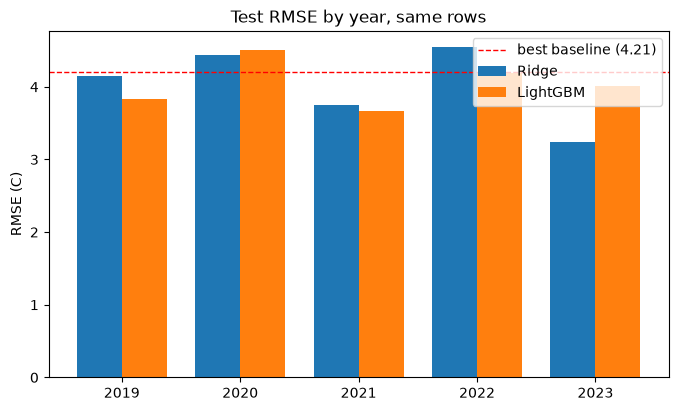

In [7]:
years = sorted(test['year'].unique())
rows = test[same_rows]

def by_year(p):
    p = pd.Series(p, index=test.index)[same_rows]
    return [rmse(rows.loc[rows['year'] == y, TARGET], p[rows['year'] == y]) for y in years]

x = np.arange(len(years))
w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - w / 2, by_year(pred), w, label='Ridge')
ax.bar(x + w / 2, by_year(pred_lgbm), w, label='LightGBM')
ax.axhline(4.21, color='red', ls='--', lw=1, label='best baseline (4.21)')
ax.set_xticks(x, years)
ax.set_ylabel('RMSE (C)')
ax.set_title('Test RMSE by year, same rows')
ax.legend()
plt.show()

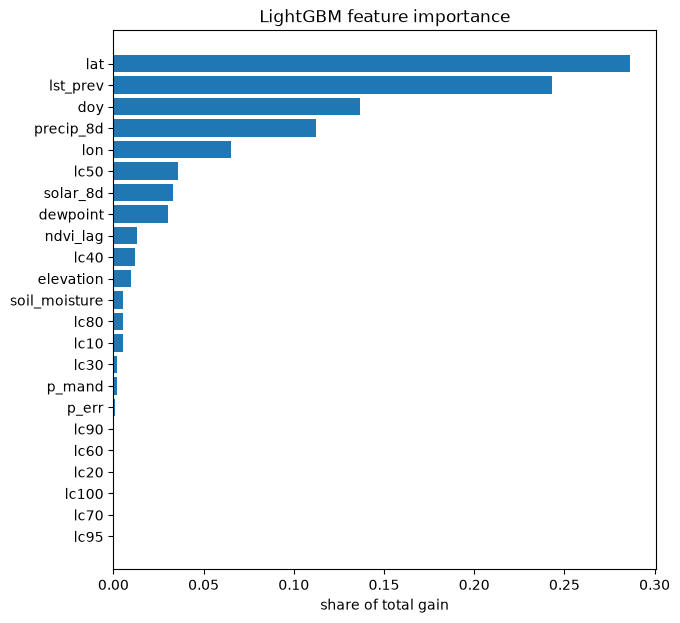

In [8]:
imp = pd.Series(lgbm.booster_.feature_importance(importance_type='gain'), index=FEATURES)
imp = (imp / imp.sum()).sort_values()

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(imp.index, imp.values)
ax.set_xlabel('share of total gain')
ax.set_title('LightGBM feature importance')
plt.show()